# LEAF-1 embedding, genomic bins, and their early fusion

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Does adding coordinate-level features to the LEAF-1 embedding help cfDNA
classification at 100k fragments per sample? Three representations, scored on
the same folds and reps:

* **LEAF-1 embedding** alone.
* **Genomic bins only**: fragment counts per bin, log1p, top-K bins by variance
  (K in {100, 1000}, inner CV), StandardScaler, logistic regression.
* **Early fusion**: the bins and the embedding concatenated into one feature
  matrix, same pipeline.

Each row is one bin resolution, labelled by bin size. The source tables index
it by the number of genome-wide bins instead -- the reverse order: 10,000 bins
are ~310 kb each (labelled 300kb), 30,000 ~103 kb (100kb), 100,000 ~31 kb
(30kb) and 300,000 ~10 kb (10kb), for a 3.1 Gb genome. The source figure's
"10k genomic bins" is therefore the coarsest row, 300kb. Bars are the pooled mean AUC with BCa 95% CI over 4 seeds x 5 folds x
10 reps (n = 200 per bar). The late-fusion arm in the source table is not
drawn, as in the source figure; the last cell prints the paired differences a
legend needs.

Panel:
- `cfdna_hybrid_emb_bin_auc`: a-d, one row per bin count.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

BIN_COUNTS = [10000, 30000, 100000, 300000]
GENOME_BP = 3.1e9
TARGETS = (["cancer_vs_healthy"]
           + [f"{c}_cancer_vs_healthy" for c in ("Bile_duct", "Breast", "Colorectal", "Gastric",
                                                 "Lung", "Ovarian", "Pancreatic")]
           + [f"{c}_cancer_vs_other_cancers" for c in ("Bile_duct", "Breast", "Colorectal", "Gastric",
                                                       "Lung", "Ovarian", "Pancreatic")])
LABELS = {t: t.replace("_cancer_vs_other_cancers", " vs other").replace("_cancer_vs_healthy", " vs healthy")
               .replace("_", " ") for t in TARGETS}
LABELS["cancer_vs_healthy"] = "Pan-cancer vs healthy"
# LEAF-1 in its blue, the bin baseline in Fig. 4's comparator grey, the fusion
# in Okabe-Ito green.
METHODS = [("Embedding", "LEAF-1 embedding", OKABE_ITO["blue"]),
           ("Bin only", "Genomic bins only", "#BCBCBC"),
           ("Hybrid", "LEAF-1 + bins (early fusion)", OKABE_ITO["green"])]
INK, MUTED, GRID = "#1A1A1A", "#666666", "#E5E5E5"
PANEL_RC = {"font.size": 6, "axes.labelsize": 6.5, "xtick.labelsize": 5.5,
            "ytick.labelsize": 5.5, "legend.fontsize": 6}

auc = pd.read_csv(DATA / "cfdna_hybrid_emb_bin_auc.csv", float_precision="round_trip")
gain = pd.read_csv(DATA / "cfdna_hybrid_emb_bin_paired_gain.csv", float_precision="round_trip")
assert set(auc.n_pairs) == {200} and set(auc.n_seeds) == {4}
plot_df = auc[auc.method.isin([m for m, _, _ in METHODS]) & auc.n_bins.isin(BIN_COUNTS)].copy()
print(plot_df.groupby(["n_bins", "method"]).mean_auc.mean().unstack().round(3).to_string())


# Rows are labelled by bin size, rounded the way the scATAC panels round them
# ("Coordinate bins 300kb" is 310 kb there too). Exact sizes, 3.1 Gb / count:
# 310, 103, 31 and 10.3 kb.
BIN_LABEL = {10000: "300kb", 30000: "100kb", 100000: "30kb", 300000: "10kb"}
for n, lab in BIN_LABEL.items():
    exact = GENOME_BP / n / 1e3
    assert abs(exact / float(lab[:-2]) - 1) < 0.05, (n, lab, exact)


def bin_title(n):
    return f"{BIN_LABEL[n]} genomic bins"

method  Bin only  Embedding  Hybrid
n_bins                             
10000      0.624       0.87   0.866
30000      0.612       0.87   0.866
100000     0.575       0.87   0.867
300000     0.592       0.87   0.867


saved: cfdna/output/cfdna_hybrid_emb_bin_auc.pdf
saved: cfdna/output/cfdna_hybrid_emb_bin_auc.png
saved: cfdna/output/cfdna_hybrid_emb_bin_auc.svg
saved: cfdna/output/cfdna_hybrid_emb_bin_auc.tsv


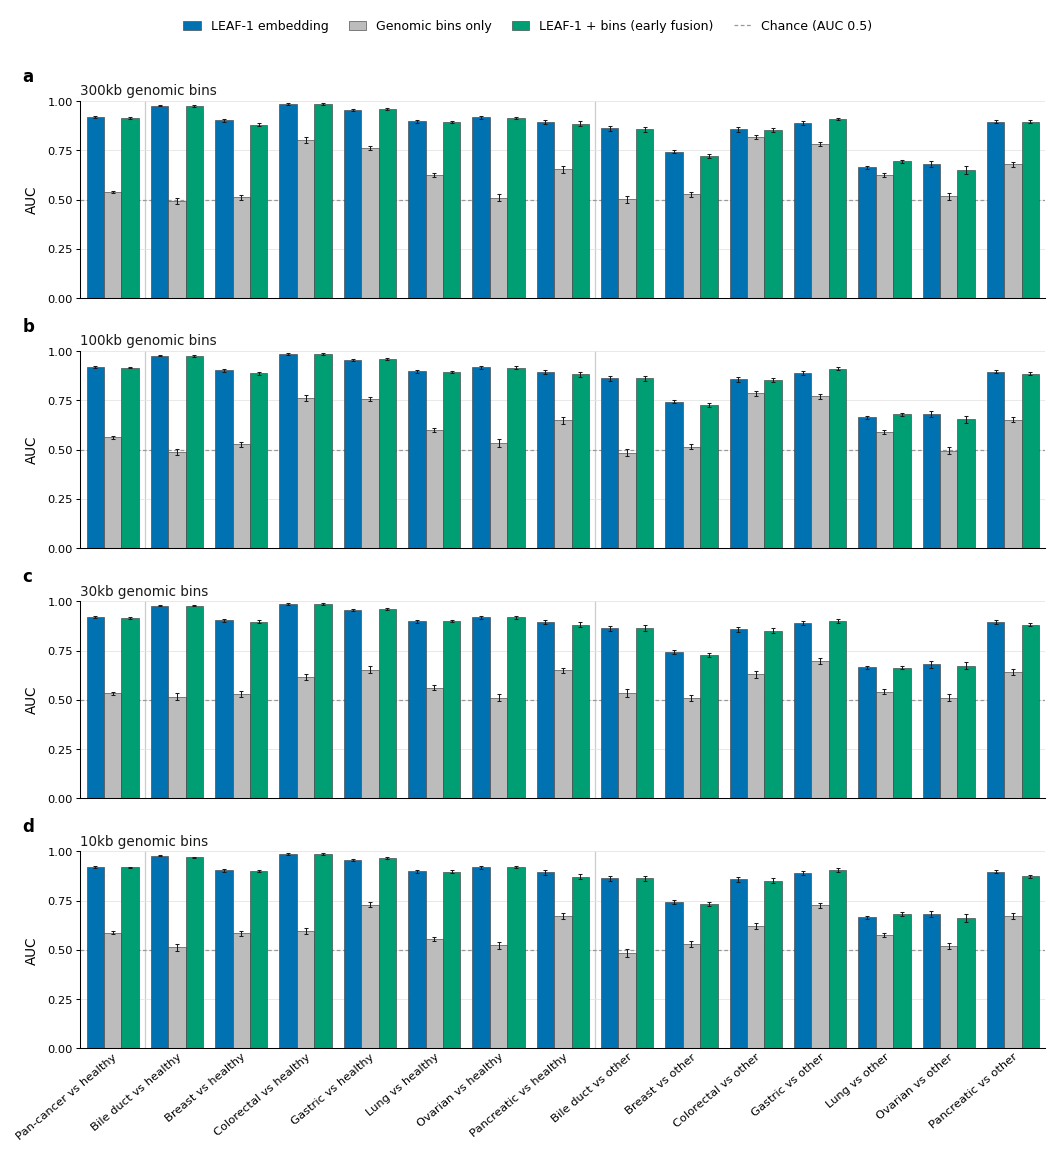

In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(PANEL_RC):
    fig, axes = plt.subplots(len(BIN_COUNTS), 1, figsize=(7.08, 7.6), sharex=True)
    x = np.arange(len(TARGETS)); w = 0.27
    for r, (ax, nb) in enumerate(zip(axes, BIN_COUNTS)):
        d = plot_df[plot_df.n_bins == nb].set_index(["target", "method"])
        for k, (m, _, color) in enumerate(METHODS):
            mean = d.loc[[(t, m) for t in TARGETS], "mean_auc"].to_numpy()
            lo = d.loc[[(t, m) for t in TARGETS], "ci_low"].to_numpy()
            hi = d.loc[[(t, m) for t in TARGETS], "ci_high"].to_numpy()
            pos = x + (k - 1) * w
            ax.bar(pos, mean, width=w, color=color, edgecolor="#444444", linewidth=0.3, zorder=2)
            ax.errorbar(pos, mean, yerr=[mean - lo, hi - mean], fmt="none", ecolor=INK,
                        elinewidth=0.5, capsize=1.0, capthick=0.5, zorder=3)
        ax.axhline(0.5, color="#999999", linestyle=(0, (3, 2)), linewidth=0.6, zorder=1)
        for xv in (0.5, 7.5):          # pan-cancer | vs healthy | vs other cancers
            ax.axvline(xv, color="#CCCCCC", linewidth=0.6, zorder=0)
        ax.set_ylim(0, 1.0); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
        ax.yaxis.grid(True, color=GRID, linewidth=0.4, zorder=0); ax.set_axisbelow(True)
        ax.set_xlim(-0.5, len(TARGETS) - 0.5)
        ax.set_ylabel("AUC")
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", length=2, pad=1.5, width=0.5)
        ax.tick_params(axis="x", length=0)
        ax.set_title(bin_title(nb), loc="left", fontsize=6.5, color=INK, pad=3)
        ax.text(-0.06, 1.08, "abcd"[r], transform=ax.transAxes, fontsize=8,
                fontweight="bold", va="bottom", ha="left")
    axes[-1].set_xticks(x)
    axes[-1].set_xticklabels([LABELS[t] for t in TARGETS], rotation=40, ha="right",
                             rotation_mode="anchor")
    handles = [Patch(facecolor=c, edgecolor="#444444", linewidth=0.3, label=lab) for _, lab, c in METHODS]
    handles.append(Line2D([], [], color="#999999", linestyle=(0, (3, 2)), linewidth=0.6,
                          label="Chance (AUC 0.5)"))
    fig.tight_layout(h_pad=1.1, rect=(0, 0, 1, 0.965))
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=4,
               frameon=False, handlelength=1.4, columnspacing=1.6, borderaxespad=0)

    savefig(fig, OUT, "cfdna_hybrid_emb_bin_auc",
            data=plot_df.sort_values(["n_bins", "target", "method"]).reset_index(drop=True))
    plt.show()

In [4]:
# ── Numbers for the figure legend ─────────────────────────────────────────────
# Paired per (seed, fold, rep) differences from the source summary, with BCa 95% CI.
for comp in ("Hybrid - Embedding", "Hybrid - Bin only"):
    print(comp)
    for nb in BIN_COUNTS:
        g = gain[(gain.comparison == comp) & (gain.n_bins == nb)]
        up = int((g.ci_low > 0).sum()); down = int((g.ci_high < 0).sum())
        print(f"  {nb:>7,} bins: mean delta AUC {g.mean_delta_auc.mean():+.4f} over {len(g)} tasks; "
              f"CI above 0 in {up}, below 0 in {down}, overlapping 0 in {len(g) - up - down}")
emb = plot_df[plot_df.method == "Embedding"].groupby("n_bins").mean_auc.mean()
print("LEAF-1 embedding mean AUC per bin row (should not vary):", emb.round(4).to_dict())

Hybrid - Embedding
   10,000 bins: mean delta AUC -0.0038 over 15 tasks; CI above 0 in 2, below 0 in 7, overlapping 0 in 6
   30,000 bins: mean delta AUC -0.0035 over 15 tasks; CI above 0 in 3, below 0 in 7, overlapping 0 in 5
  100,000 bins: mean delta AUC -0.0032 over 15 tasks; CI above 0 in 2, below 0 in 6, overlapping 0 in 7
  300,000 bins: mean delta AUC -0.0030 over 15 tasks; CI above 0 in 3, below 0 in 6, overlapping 0 in 6
Hybrid - Bin only
   10,000 bins: mean delta AUC +0.2424 over 15 tasks; CI above 0 in 15, below 0 in 0, overlapping 0 in 0
   30,000 bins: mean delta AUC +0.2544 over 15 tasks; CI above 0 in 15, below 0 in 0, overlapping 0 in 0
  100,000 bins: mean delta AUC +0.2914 over 15 tasks; CI above 0 in 15, below 0 in 0, overlapping 0 in 0
  300,000 bins: mean delta AUC +0.2746 over 15 tasks; CI above 0 in 15, below 0 in 0, overlapping 0 in 0
LEAF-1 embedding mean AUC per bin row (should not vary): {10000: 0.8699, 30000: 0.8699, 100000: 0.8699, 300000: 0.8699}
